In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

with open("../plot/plotting_config.yaml") as fp:
    config = yaml.safe_load(fp)

In [2]:
data_folder = "../data/symmetric_area_difference"
figure_folder = "../figures"

In [3]:
Path(figure_folder).mkdir(parents=True, exist_ok=True)

In [4]:
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    """
    https://stackoverflow.com/a/18926541/4737417
    by unutbu, CC BY-SA 3.0
    """
    new_cmap = LinearSegmentedColormap.from_list(
        "trunc({n},{a:.2f},{b:.2f})".format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)),
    )
    return new_cmap

In [5]:
OkabeIto = {
    "orange": "#e69f00",
    "skyblue": "#56b4e9",
    "bluishgreen": "#009e73",
    "yellow": "#f0e442",
    "blue": "#0072b2",
    "vermilion": "#d55e00",
    "reddishpurple": "#cc79a7",
    "black": "#000000",
}

In [6]:
cmap_distr = LinearSegmentedColormap.from_list(
    "districts", ["white", OkabeIto["blue"]], N=25
)
cmap_adm10 = LinearSegmentedColormap.from_list(
    "districts", ["white", OkabeIto["yellow"]], N=25
)
cmap_road1 = LinearSegmentedColormap.from_list(
    "districts", ["white", OkabeIto["orange"]], N=25
)
cmap_road2 = LinearSegmentedColormap.from_list(
    "districts", ["white", OkabeIto["skyblue"]], N=25
)


cmap_distr = truncate_colormap(cmap_distr, 0.4, 1)
cmap_adm10 = truncate_colormap(cmap_adm10, 0.4, 1)
cmap_road1 = truncate_colormap(cmap_road1, 0.4, 1)
cmap_road2 = truncate_colormap(cmap_road2, 0.4, 1)

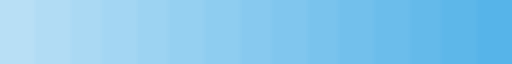

In [7]:
cmap_road2

In [8]:
def agg_fretchet(df):
    temp = df.copy()
    temp["area_symmdiff"] = temp["area_symmdiff"] / 1e6
    return (
        temp.groupby(["run", "resolution", "community_id"])["area_symmdiff"]
        .mean()
        .reset_index()
    )

In [ ]:
fr_distr = pd.read_csv(f"{data_folder}/communities_vs_districts_area_symmdiff.csv")
fr_distr = agg_fretchet(fr_distr)
fr_adm10 = pd.read_csv(f"{data_folder}/communities_vs_neighborhoods_area_symmdiff.csv")
fr_adm10 = agg_fretchet(fr_adm10)
fr_road1 = pd.read_csv(f"{data_folder}/communities_vs_primary_area_symmdiff.csv")
fr_road1 = agg_fretchet(fr_road1)
fr_road2 = pd.read_csv(f"{data_folder}/communities_vs_secondary_area_symmdiff.csv")
fr_road2 = agg_fretchet(fr_road2)

In [ ]:
def plot(df, cmap, style="solid", ax=None, figsize=(6, 6)):
    if ax:
        fig = ax.get_figure()
    else:
        fig, ax = plt.subplots(figsize=figsize)
    sns.lineplot(
        data=df.groupby(["resolution", "run"])["area_symmdiff"].mean().reset_index(),
        x="resolution",
        y="area_symmdiff",
        hue="run",
        linestyle=style,
        ax=ax,
        legend=False,
        palette=cmap,
    )
    ax.set_xlabel("Resolution")
    ax.set_ylabel("Area symmetric difference ($km^2$)")

    return fig, ax

In [ ]:
fadm, aadm = plot(fr_distr, cmap_distr)
plot(fr_adm10, cmap_adm10, style="dotted", ax=aadm)

legend_elements = []
labels = ["Districts", "Neighborhoods"]
styles = ["solid", "dotted"]
lcolors = [OkabeIto["blue"], OkabeIto["yellow"]]
for l, c, s in zip(labels, lcolors, styles):
    elem = Line2D([0], [0], color=c, lw=4, linestyle=s, label=l)
    legend_elements.append(elem)

aadm.legend(handles=legend_elements, ncols=2)

for i in config["formats"]:
    fadm.savefig(
        f"{figure_folder}/area_symmdiff_administrative.{i}",
        dpi=300,
        facecolor="white",  # bbox_inches="tight",
        metadata=config["metadata"],
    )

In [ ]:
fbar, abar = plot(fr_road1, cmap_road1)
plot(fr_road2, cmap_road2, style="dotted", ax=abar)

legend_elements = []
labels = ["Primary roads", "Primary and secondary roads"]
styles = ["solid", "dotted"]
lcolors = [OkabeIto["orange"], OkabeIto["skyblue"]]
for l, c, s in zip(labels, lcolors, styles):
    elem = Line2D([0], [0], color=c, lw=4, linestyle=s, label=l)
    legend_elements.append(elem)

abar.legend(handles=legend_elements, ncols=2)

for i in config["formats"]:
    fbar.savefig(
        f"{figure_folder}/area_symmdiff_barriers.{i}",
        dpi=300,
        facecolor="white",  # bbox_inches="tight",
        metadata=config["metadata"],
    )